# E6 · Transfer by recall
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

The hippocampal-analog test: recall which stored structure is active, rather than re-derive it.

**Where we're at.** Step 1b, last experiment: the alternative way to transfer, by recall.

**Where the system is after the last experiments.** Detection works but needs about 50 steps and has a blind spot (E5).

**Where we want it.** Known structures recalled in a few steps, and new ones recognized as new.

**How this set moves it.** Stores 16 of the 32 ring patterns in a bank, filters a belief over them, and compares recall with detection: accuracy by window, re-locking after a switch, and the novelty test.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e6")
world = config.world_from(cfg)
p = cfg["e6"]

In [2]:
F.ledger("e6")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | ring | how the springs are wired |
| `n` | 5 | number of bodies |
| `bank_size` | 16 | stored structures |
| `hazard` | 0.01 | chance per step that the context changes |
| `noise` | 0.01 | measurement noise, fraction of the swing |
| `amplitude` | 0.1 | starting swing size (rad) |
| `windows` | [1, 2, 3, 5, 10, 20, 50] | window lengths (steps) |
| `static_trials` | 100 | trials per window |
| `switch_trials` | 20 | switch trials |
| `switch_step` | 150 | step at which a spring is cut |
| `total_steps` | 300 | steps per switch trial |
| `sliding_window` | 50 | window of the sliding detector (steps) |
| `novelty_windows` | [20, 50, 100] | novelty test windows (steps) |
| `novelty_trials` | 150 | novelty trials per window |
| `false_alarm` | 0.01 | false-alarm rate the novelty threshold allows |

## The question

A **structural vertex** stores a bank $G$ of gate patterns, one row $G_c$ per context. A **binding vertex** holds a belief $\pi(t)$ over them and, like any vertex, predicts and corrects:

$$\underbrace{\alpha(t+1)}_{\text{unnormalised belief}} = \underbrace{\operatorname{diag}\big(\ell(t+1)\big)}_{\text{evidence gate}}\;\underbrace{T^\top}_{\text{contexts persist}}\;\alpha(t), \qquad \pi = \frac{\alpha}{\mathbf 1^\top\alpha}, \qquad g(t) = G^\top\pi(t)$$

$$\ell_c(t+1) = \exp\!\Big(-\tfrac12\big\|\,x(t+1) - \big(I\otimes K - L(G_c)\otimes M\big)\,x(t)\big\|^2_{\Sigma^{-1}}\Big), \qquad T = (1-h)\,I + \tfrac{h}{C-1}\,(\mathbf 1\mathbf 1^\top - I)$$

A structure is new when the best stored one loses to one detected on the same window by more than a threshold $\tau$:

$$\Lambda = \min_c \sum_t \mathrm{NLL}_c(t) - \sum_t \mathrm{NLL}_{\hat g}(t) > \tau$$

**Prediction.** Recall reaches 95% within 10 steps where detection needs about 50; after a switch the binding vertex re-locks in a few steps; the likelihood ratio flags new structures.
**Pass if** recall ≥ 95% within 10 steps, re-locking is 5× faster than detection, and the error after a switch is within 1.5× of known gates.

In [3]:
runs = F.ensure_results("e6")

e6: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:59+00:00)


## The world: a ring of 5 and a bank of stored structures

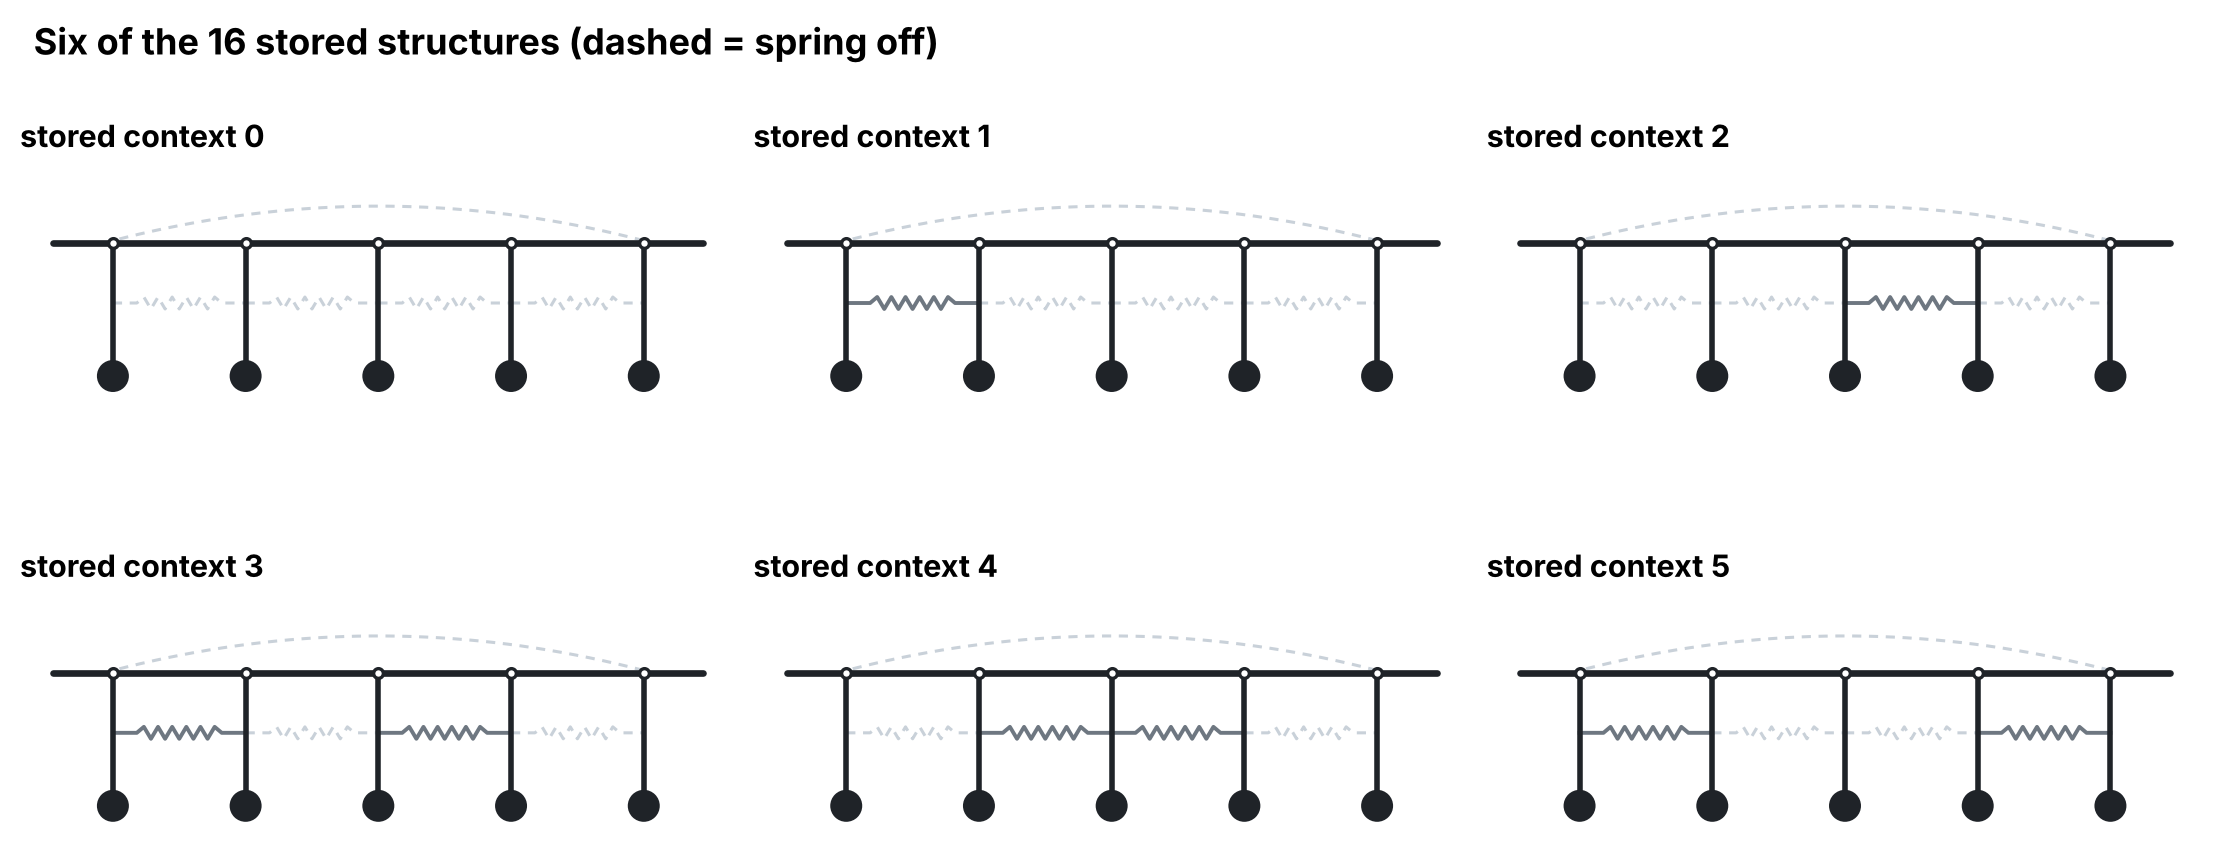

In [4]:
bank = runs[0]["arrays"]["bank_patterns"]
ring = graphs.ring(5)
F.schematics([(f"stored context {c}", 5, ring, bank[c]) for c in range(6)], cols=3,
             title=f"Six of the {len(bank)} stored structures (dashed = spring off)");

## Nominal vs actual: a switch between two stored contexts at 7.5 s

Here the nominal world is the **one-step prediction** made with the binding vertex's current best structure; blue dashed springs mark where its structure differs from the world's. Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time.

In [5]:
a = runs[0]["arrays"]
display(viz.player(a["theta_act"], a["theta_nom"], ring, a["gates_act"], dt=world.dt, tol=0.05 * p["amplitude"],
                   nominal_gates=a["gates_nom"], switch_steps=[p["switch_step"]],
                   title="Contexts switch at 7.5 s; the binding vertex follows",
                   subtitle="One-step predictions. Measurement noise is 1% of the swing, so one-step deviations of a few "
                            "10⁻³ rad are noise; tolerance 5% of the swing. Watch the blue dashed springs after the switch."))

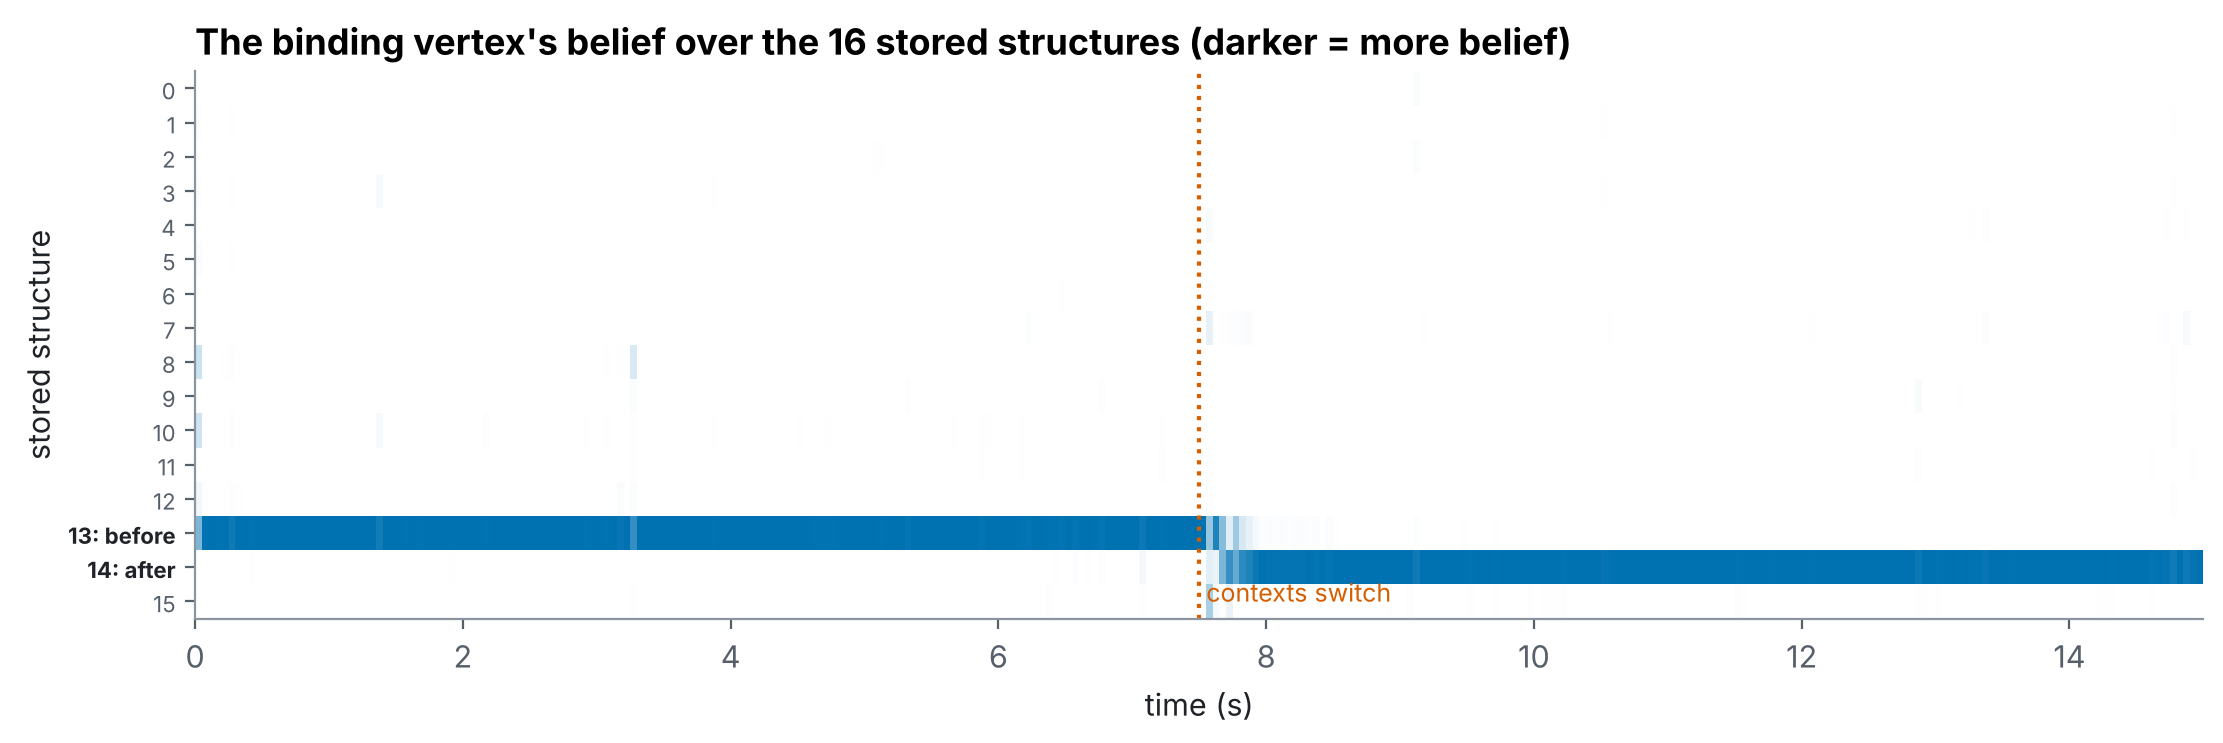

In [6]:
F.e6_belief(runs[0], world, p['switch_step']);

## Recall against detection

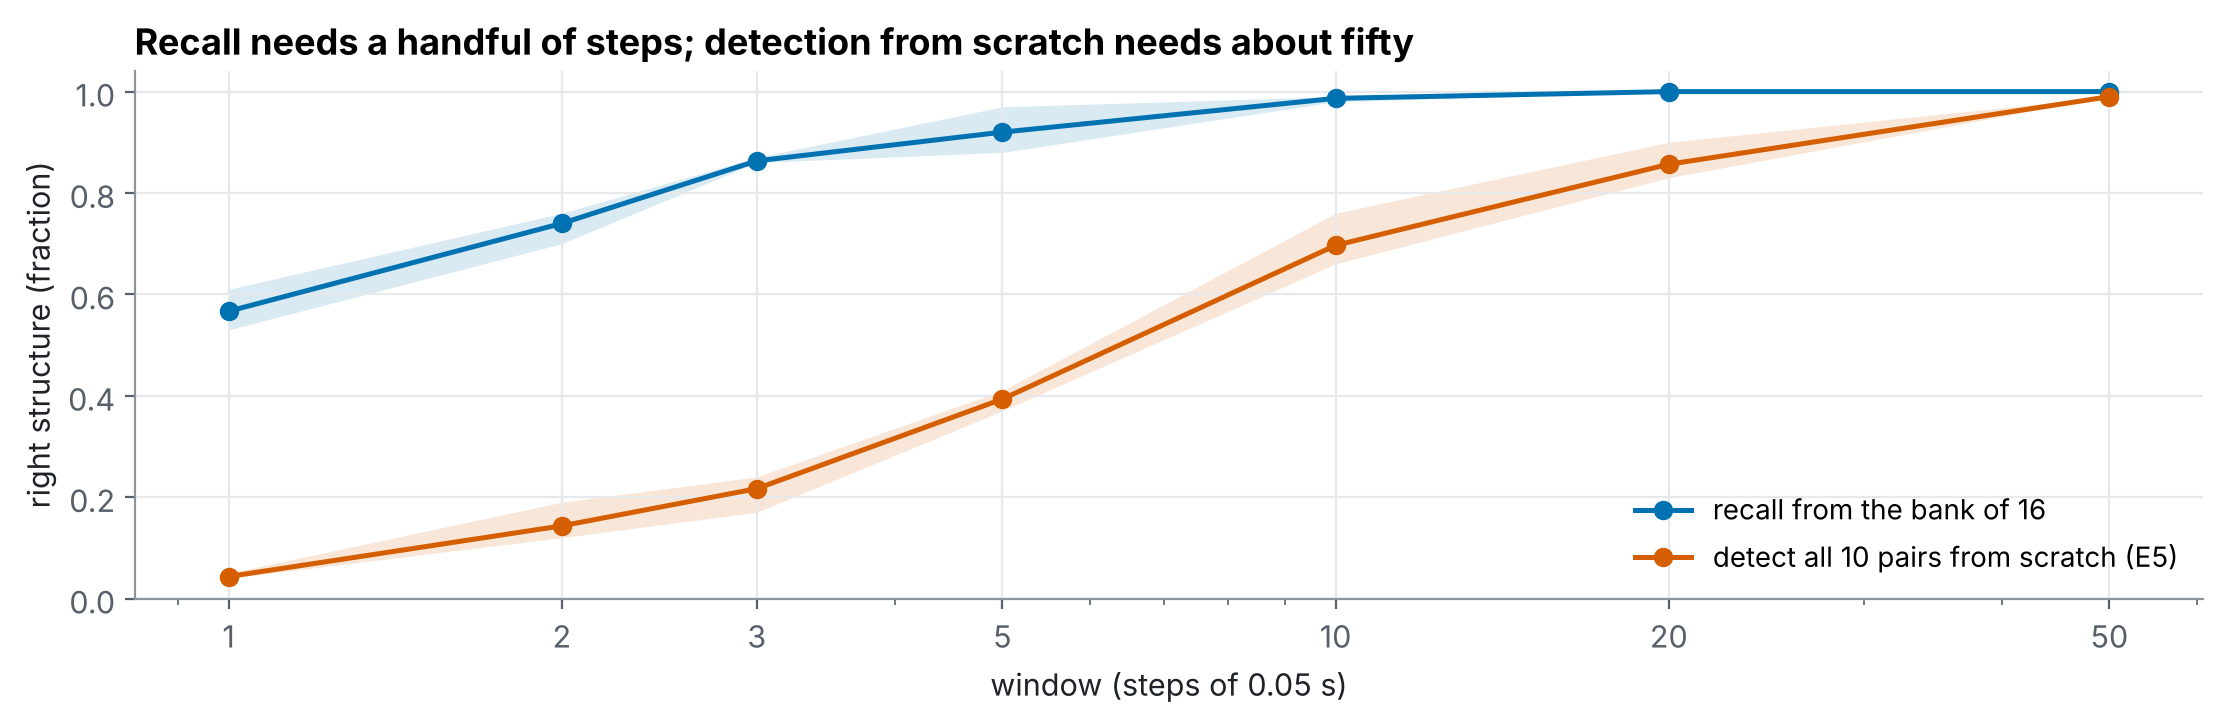

In [7]:
F.e6_recall_vs_detect(runs);

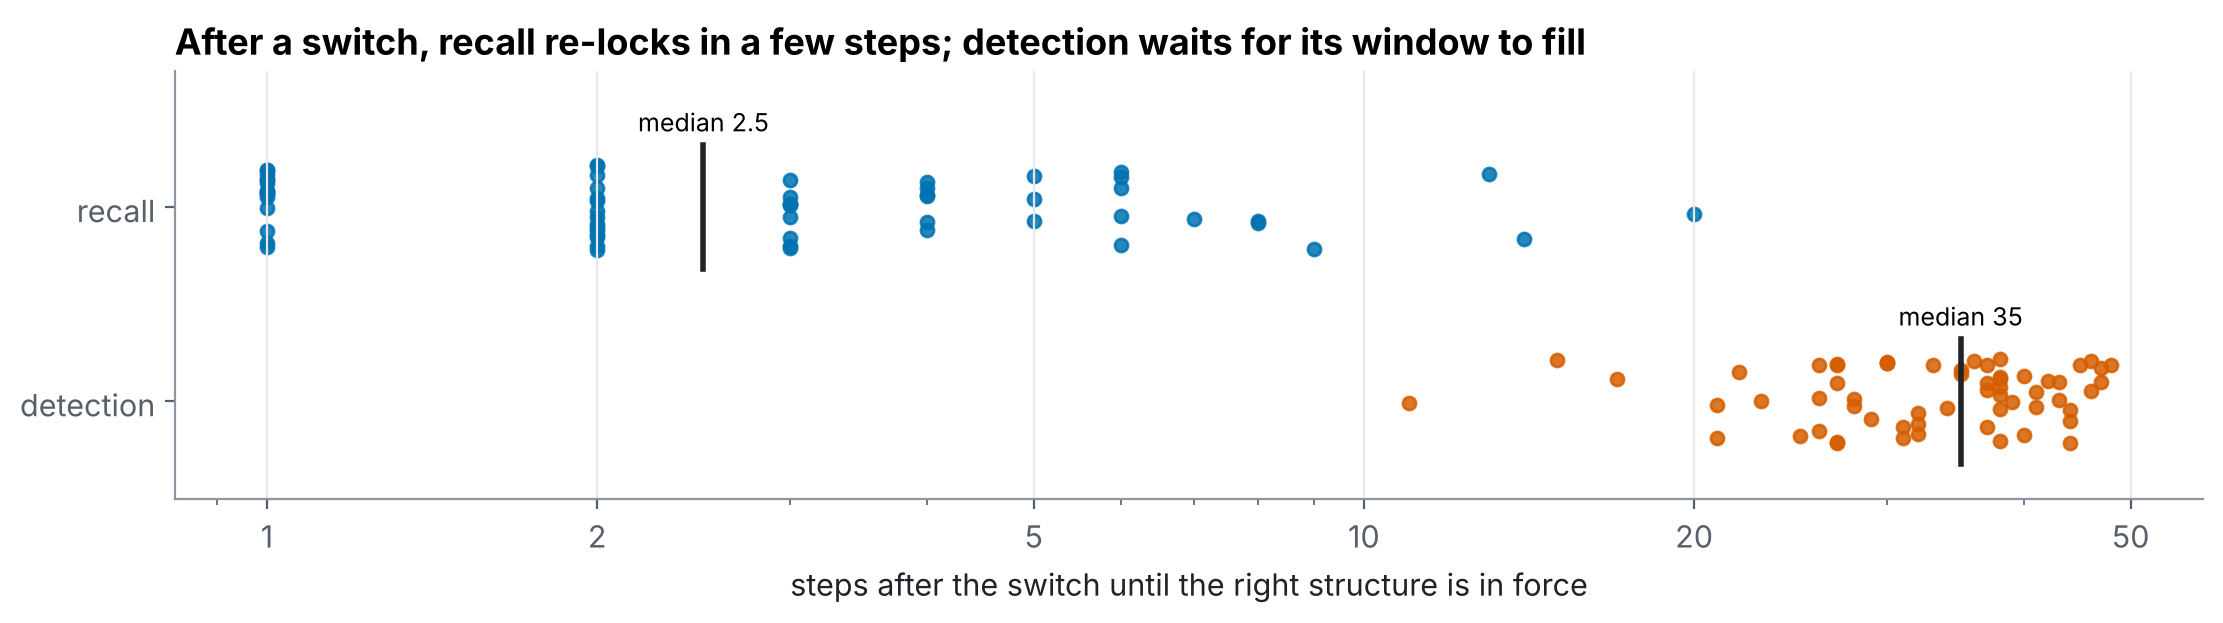

In [8]:
F.e6_relock(runs);

In [9]:
mm = [r["metrics"] for r in runs]
w = list(mm[0]["windows"])
at = lambda key, win: [x[key][w.index(win)] for x in mm]
F.say(f"From 5 steps, recall picks the right structure {viz.pct(np.mean(at('recall_accuracy', 5)))} of the time; detecting "
      f"all 10 pairs from scratch gets {viz.pct(np.mean(at('detect_accuracy', 5)))}. After a switch the binding vertex "
      f"re-locks in a median of {F.spread([x['relock_filter_median'] for x in mm])} steps, against "
      f"{F.spread([x['relock_detect_median'] for x in mm])} for a sliding 50-step detector.")

> **Finding.** From 5 steps, recall picks the right structure 92% of the time; detecting all 10 pairs from scratch gets 39%. After a switch the binding vertex re-locks in a median of 2.5 (2 to 3) steps, against 34.5 (31.5 to 36.5) for a sliding 50-step detector.

## Is this structure new?

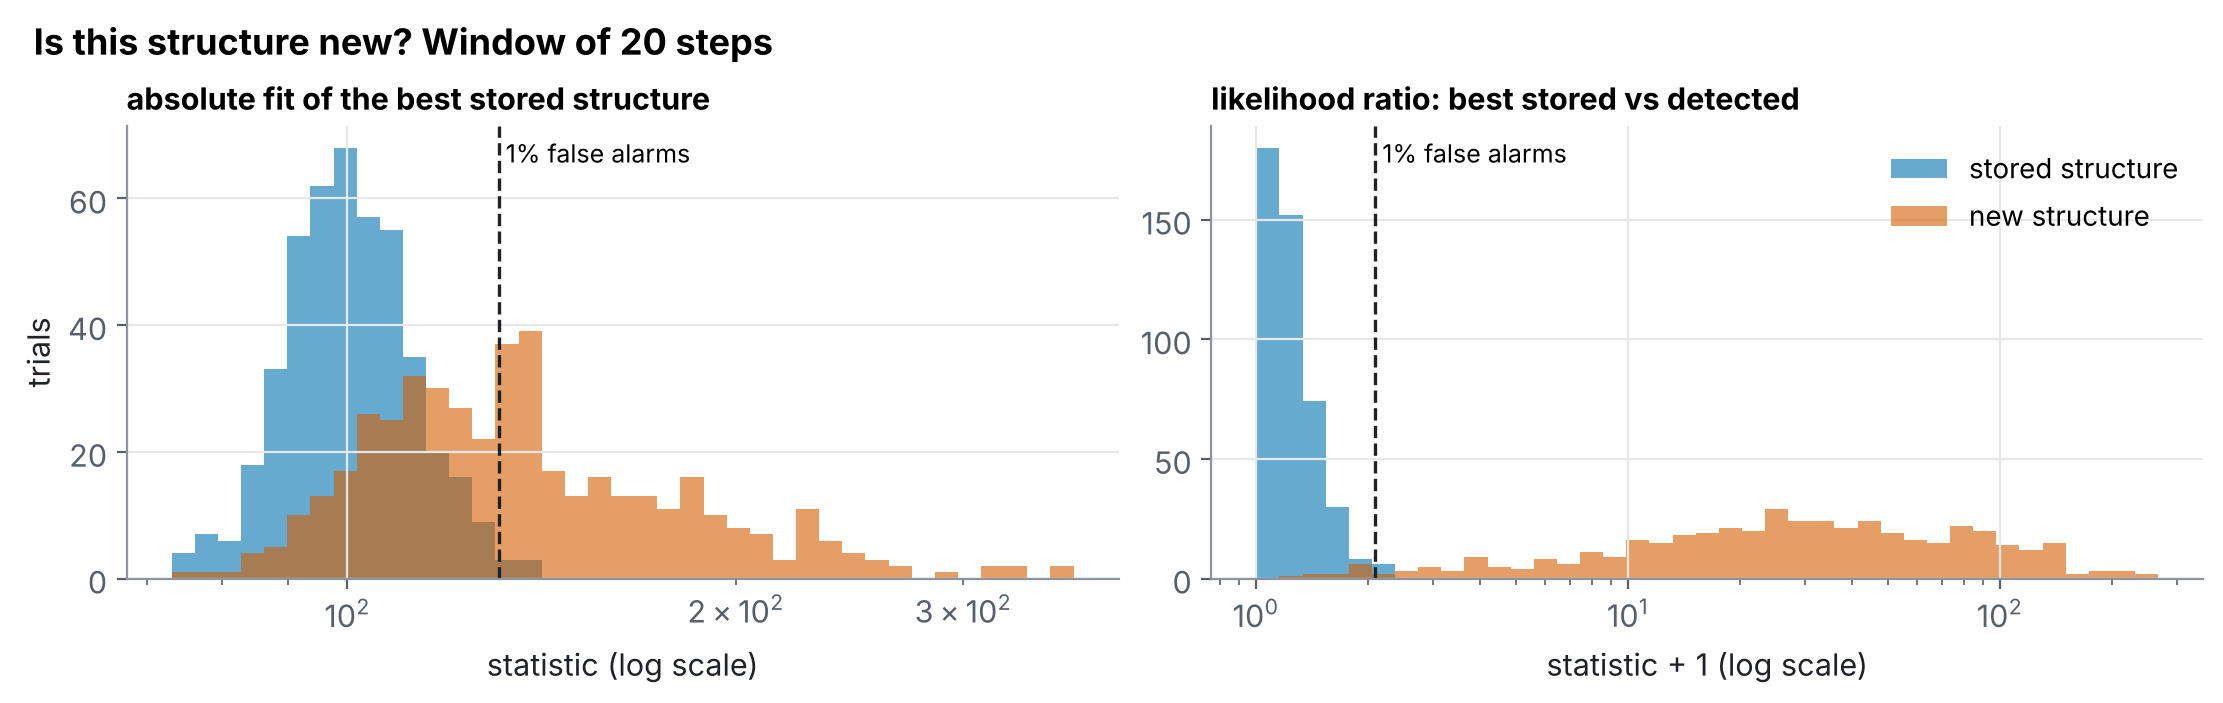

In [10]:
F.e6_novelty(runs, window=20);

In [11]:
nv = lambda win, key: [x["novelty"][str(win)][key] for x in mm]
F.say(f"With 20 steps and 1% false alarms, the likelihood ratio flags {viz.pct(np.mean(nv(20, 'glr_flagged')))} of new "
      f"structures; the absolute fit test flags {viz.pct(np.mean(nv(20, 'abs_flagged')))}. Comparing against a freshly "
      "detected structure cancels the noise that an absolute threshold has to sit above.")

> **Finding.** With 20 steps and 1% false alarms, the likelihood ratio flags 98% of new structures; the absolute fit test flags 51%. Comparing against a freshly detected structure cancels the noise that an absolute threshold has to sit above.

## Inspection report

In [12]:
err = lambda k: float(np.mean([x["error_after_switch"][k] for x in mm]))
rec10 = float(np.mean(at("recall_accuracy", 10)))
speed = float(np.mean([x["relock_detect_median"] for x in mm]) / np.mean([x["relock_filter_median"] for x in mm]))
viz.inspection_report([
    {"characteristic": "Recall within 10 steps", "nominal": rec10, "tolerance": "≥ 0.95", "status": "in" if rec10 >= 0.95 else "out"},
    {"characteristic": "Re-lock speed-up over sliding detection", "nominal": speed, "tolerance": "≥ 5×",
     "status": "in" if speed >= 5 else "out"},
    {"characteristic": "Error after a switch ÷ known gates", "nominal": err("filter") / err("oracle"), "actual": 1.0,
     "deviation": err("filter") / err("oracle") - 1, "tolerance": 0.5},
    {"characteristic": "New structures flagged in 20 steps (likelihood ratio)", "nominal": float(np.mean(nv(20, "glr_flagged"))),
     "tolerance": "at 1% false alarms", "status": None},
], title="Transfer by recall, across seeds")

**Transfer by recall, across seeds**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| Recall within 10 steps | 0.9867 | — | — | ≥ 0.95 | ✓ **in** |
| Re-lock speed-up over sliding detection | 13.8 | — | — | ≥ 5× | ✓ **in** |
| Error after a switch ÷ known gates | 1.09 | 1 | 0.08952 | ±0.5 | ✓ **in** |
| New structures flagged in 20 steps (likelihood ratio) | 0.9778 | — | — | at 1% false alarms | — |

## Log

In [13]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:59+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:29:00+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:29:01+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |